In [ ]:
import numpy as np
import os
import utils
import matplotlib.pyplot as plt
import dijkstra
import a_star
import bfs
import greedy

def test_algorithm(planner, start, goal, ax, grid_map, title):
  
  # Check if the planner is a costmap planner( inherits from Dijkstra)
  if issubclass(type(planner), dijkstra.Dijkstra):
    utils.plot_costmap(planner.costmap, title, ax)
  else:
    utils.plot_gridmap(grid_map, title, ax)
  path = planner.plan(start, goal, ax)
  planner.plot_path(path, ax)  

def compare_motion(planner_class, start, goal, grid_map):
  fig, axes = plt.subplots(1, 2, figsize=(12,6))
  fig.suptitle(f'Comparing 4 and 8 connectivity for {planner_class.__name__}')
  ax = axes[0]
  ax2 = axes[1]
  planner = planner_class(grid_map, utils.Movements4Connectivity())
  test_algorithm(planner, start, goal, ax, grid_map, 'planner 4')
  planner = planner_class(grid_map, utils.Movements8Connectivity())
  test_algorithm(planner, start, goal, ax2, grid_map, 'planner 8')
  plt.show()

def compare_algorithms(start, goal, grid_map, movements):
  fig, axes = plt.subplots(2, 2, figsize=(12,12))
  fig.suptitle(f'Comparing algorithms on the same map with {movements.__class__.__name__}')
  algorithms = [bfs.BFS, dijkstra.Dijkstra, greedy.Greedy, a_star.AStar]
  
  for i, planner_class in enumerate(algorithms):
    ax = axes[i//axes.shape[1], i%axes.shape[1]]
    planner = planner_class(grid_map, movements)
    test_algorithm(planner, start, goal, ax, grid_map, planner_class.__name__)
  plt.show()


In [9]:
relative_path = "../2D_maps/map1.png"
print("Testing dijkstra on map1.png")
print("current directory: ", os.getcwd())
curr_dir = os.getcwd()
                            
map_path = os.path.join(curr_dir, relative_path)

xy_reso = 3
_, grid_map = utils.get_map(map_path, xy_reso)
start = np.array([20, 0])
goal = np.array([0, 20])


Testing dijkstra on map1.png
current directory:  d:\guida corso\planning_control_methodss\Path_Planners
Map size: (64, 64)
Grid Map size: (22, 22)


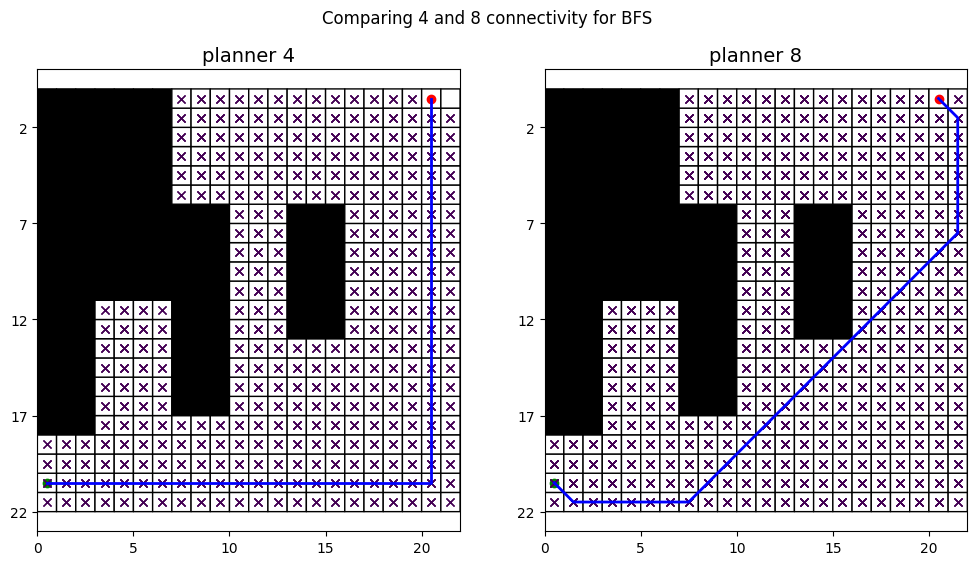

In [10]:
compare_motion(bfs.BFS, start, goal, grid_map)

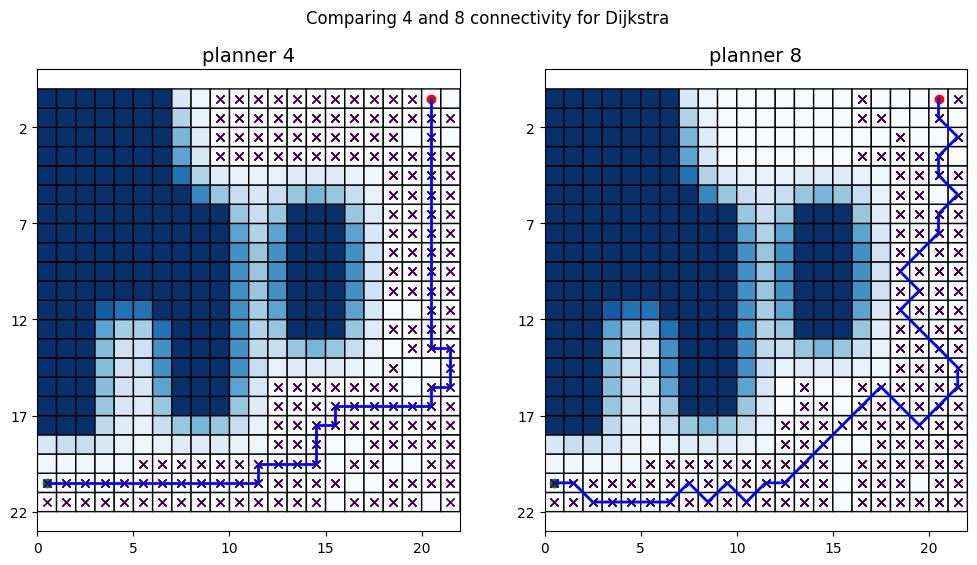

In [11]:
compare_motion(dijkstra.Dijkstra, start, goal, grid_map)

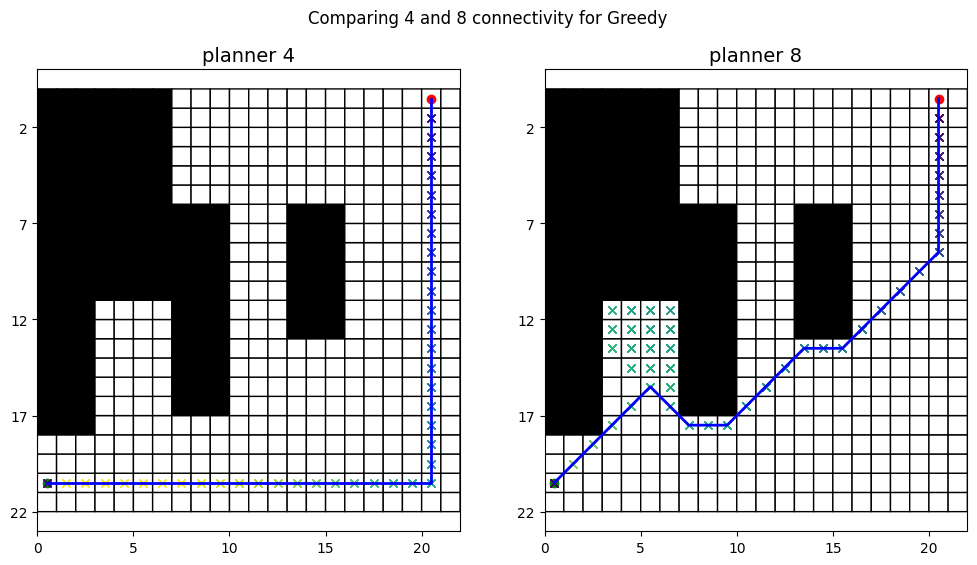

In [12]:
compare_motion(greedy.Greedy, start, goal, grid_map)

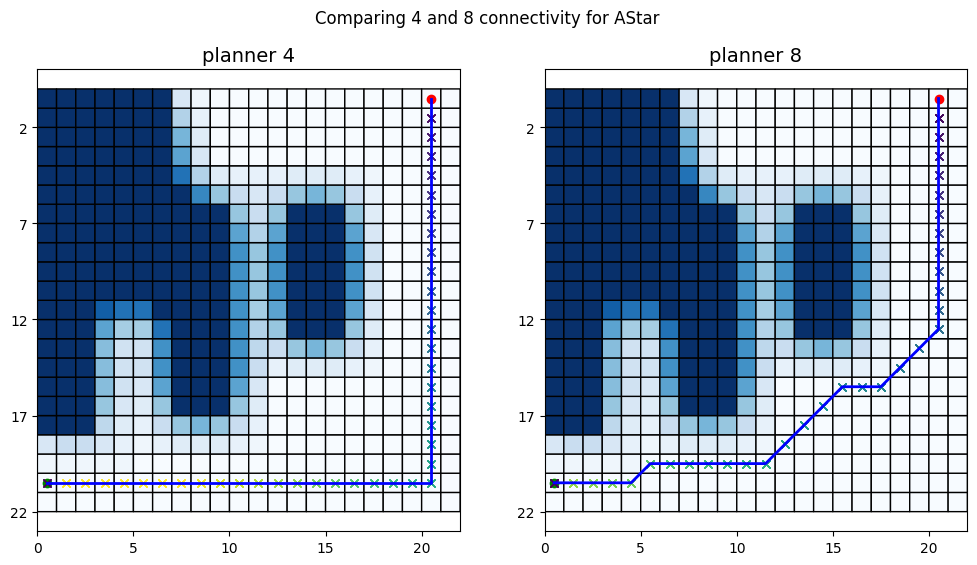

In [13]:
compare_motion(a_star.AStar, start, goal, grid_map)

AttributeError: 'numpy.ndarray' object has no attribute 'pcolor'

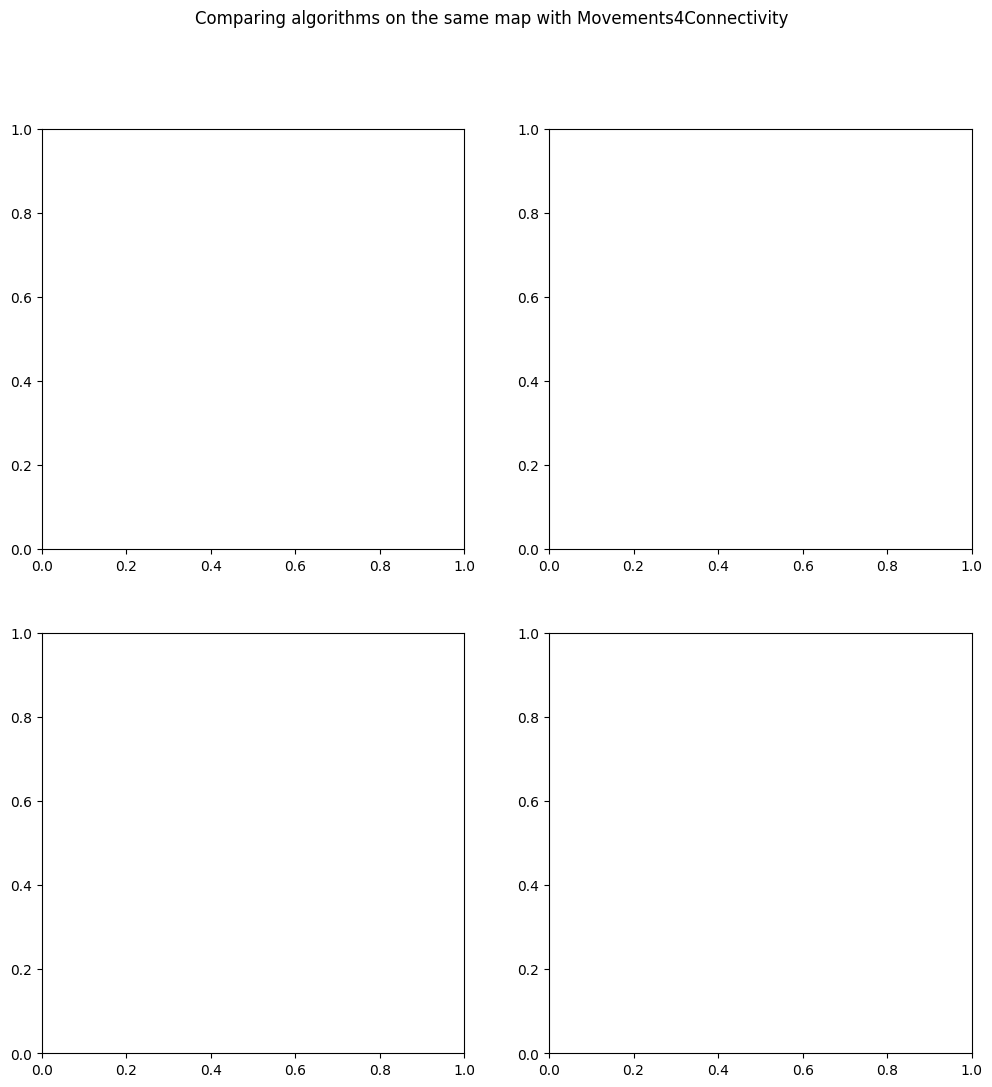

In [15]:
compare_algorithms(start, goal, grid_map, utils.Movements4Connectivity())